## Abstract

Placeholder. Write this last, in 280 characters or fewer. The framing depends on how Question 3 resolves.

----

:::{.callout-note title="AI usage disclosure" collapse="true"}
This is a placeholder for the AI usage disclosure. Once all authors sign the AI code form on AirTable, SlackBot will message you an AI disclosure that you should place here.
:::

## Purpose

Placeholder. This section will state why the work was done, the key takeaway, and who it is for.

The argument to make here: binder design campaigns run with ESMFold2 return mostly &alpha;-helical binders, and a designer who needs a different fold has no obvious knob to turn. We add a secondary-structure term to the design loss, show what it buys and what it costs, and report whether the resulting designs are worth trialing.

Primary audience: people running structure-prediction-based binder design campaigns, and people interested in what can be steered in a folding model after training.

## Introduction

Placeholder. Three claims to establish, each needing citations added to `ref.bib`:

1. **Binder design tends to be &alpha;-rich.** Design pipelines built on structure predictors return helical binders far more often than any other fold class. To write: how general this is across pipelines, and what is already known about why.
2. **Increasing structural diversity yields better campaigns.** A more structurally diverse design pool improves the odds that a campaign yields a binder that works experimentally. To write: the evidence for this, and how diversity is usually pursued today.
3. **Sometimes success is locked behind &beta;-rich designs.** Some epitopes are not addressable by a helical bundle. To write: concrete examples where a &beta;-rich binder was the one that worked.

These three claims motivate the three questions that structure the rest of the notebook.

:::{.callout-note collapse="true" title="Reproducing this notebook"}
**Nothing here is tracked in the repository, and nothing needs an account.** Both of this pub's inputs are deposited, and the notebook fetches what is missing on first execution: `make execute` downloads them from a public S3 bucket, falling back to [Zenodo](https://zenodo.org) if S3 is unreachable. The downloaded archive is kept beside the extracted data as the marker that says it arrived that way, so subsequent runs find it and skip straight to loading. `make preview` renders from the cached results in `_freeze/` and downloads nothing at all.

The two inputs are deposited for different reasons, and the difference is whether they can be derived.

**The natural binder reference set is derived here.** What the deposit holds is the *inputs*: the frozen RCSB search results and the gzipped structures. The notebook runs the analysis over them, measuring every chain with the same `analysis.secondary_structure` code that measures the designs. So the measurement is reproduced on every fresh clone rather than taken on trust. Recording the search results, not just the query, is also what pins the set: the RCSB recomputes its sequence-identity clusters as the PDB grows, so a live query drifts where a recorded one does not.

**The design campaigns are not derived here.** Designing needs GPUs and costs real money, and the loop is not seed-reproducible: across two runs of an identically configured arm, no seed reproduced its own result and per-seed interface pTM moved by 0.14 to 0.20. A rerun produces *different* designs rather than the same ones, so the deposit holds the finished per-design tables and the notebook reads them.

### Regenerating everything from source

```bash
modal deploy src/analysis/modal_app.py
FORCE_RERUN=1 make execute
```

`FORCE_RERUN=1` deletes every derivable file, skips the deposit entirely, queries the live RCSB, and designs all 450 binders again on [Modal](https://modal.com). It is checked for a Modal token *before* anything is deleted, so a missing account cannot leave you with neither the data nor the means to make it. The grid is five targets by three loss arms by thirty seeds at 150 optimization steps, which took 78 minutes at 30 concurrent H100s; `ESMFOLD2_SS_MAX_CONTAINERS` sets that concurrency and defaults to 30, so lower it to match your own quota. Unset `FORCE_RERUN` afterwards, or every later execution will delete and regenerate again.

Expect a regenerated run to reproduce the conclusions rather than the numbers. The designs will differ for the reason above, and the reference set may differ slightly because the live query re-clusters.
:::

In [1]:
#| include: false

import warnings

import pandas as pd
from analysis import (
    campaign,
    composition,
    deposit,
    figures,
    paths,
    reference,
    secondary_structure,
    targets,
)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)
paths.ensure_dirs()

TARGETS = list(targets.TARGET_SPECS)
ARMS = list(targets.CAMPAIGN_ARMS)

In [2]:
#| include: false

if deposit.force_rerun():
    deposit.require_modal()
    removed = deposit.clear_generated()
    print(f"{deposit.FORCE_RERUN_ENV}=1: removed {len(removed)} generated paths")
    campaign.ensure(TARGETS, ARMS)
else:
    deposit.DESIGN_TABLES.fetch()

## ESMFold2 designs are biased towards &alpha;-helix

We tested this on the five targets the ESMFold2 preprint uses to demonstrate binder design: the EGFR domain III, the PDGFR&beta; D2&ndash;D3 tandem, the PD-L1 and CTLA-4 IgV domains, and the CD45 d3&ndash;d4 tandem. Using the paper's own examples matters, because it means any bias we find is not an artifact of targets we chose ourselves. For each we ran 30 designs with the unmodified algorithm, 150 in total, at 150 optimization steps per design.

To say whether the result is helix-*rich* we need something to be rich relative to, and a monomer is the wrong comparator: a designed binder's job is to bind. So we compare against the small chain of a natural heterodimer solved in complex with its partner &mdash; a protein known to bind something. Those come from a single query against the RCSB, which yields 2,098 such chains. Because short natural proteins are helix-biased on their own, and the designs vary in length, we resample the natural set to match the length distribution of the designs rather than pooling across lengths.

Figure 1 puts the two side by side, against binder length, in helix and in sheet.

,"natural binders, length-matched (%)",ESMFold2 vanilla designs (%)
mean helix,35.9,66.5
mean sheet,23.7,12.8
designs with zero sheet,20.3,70.0


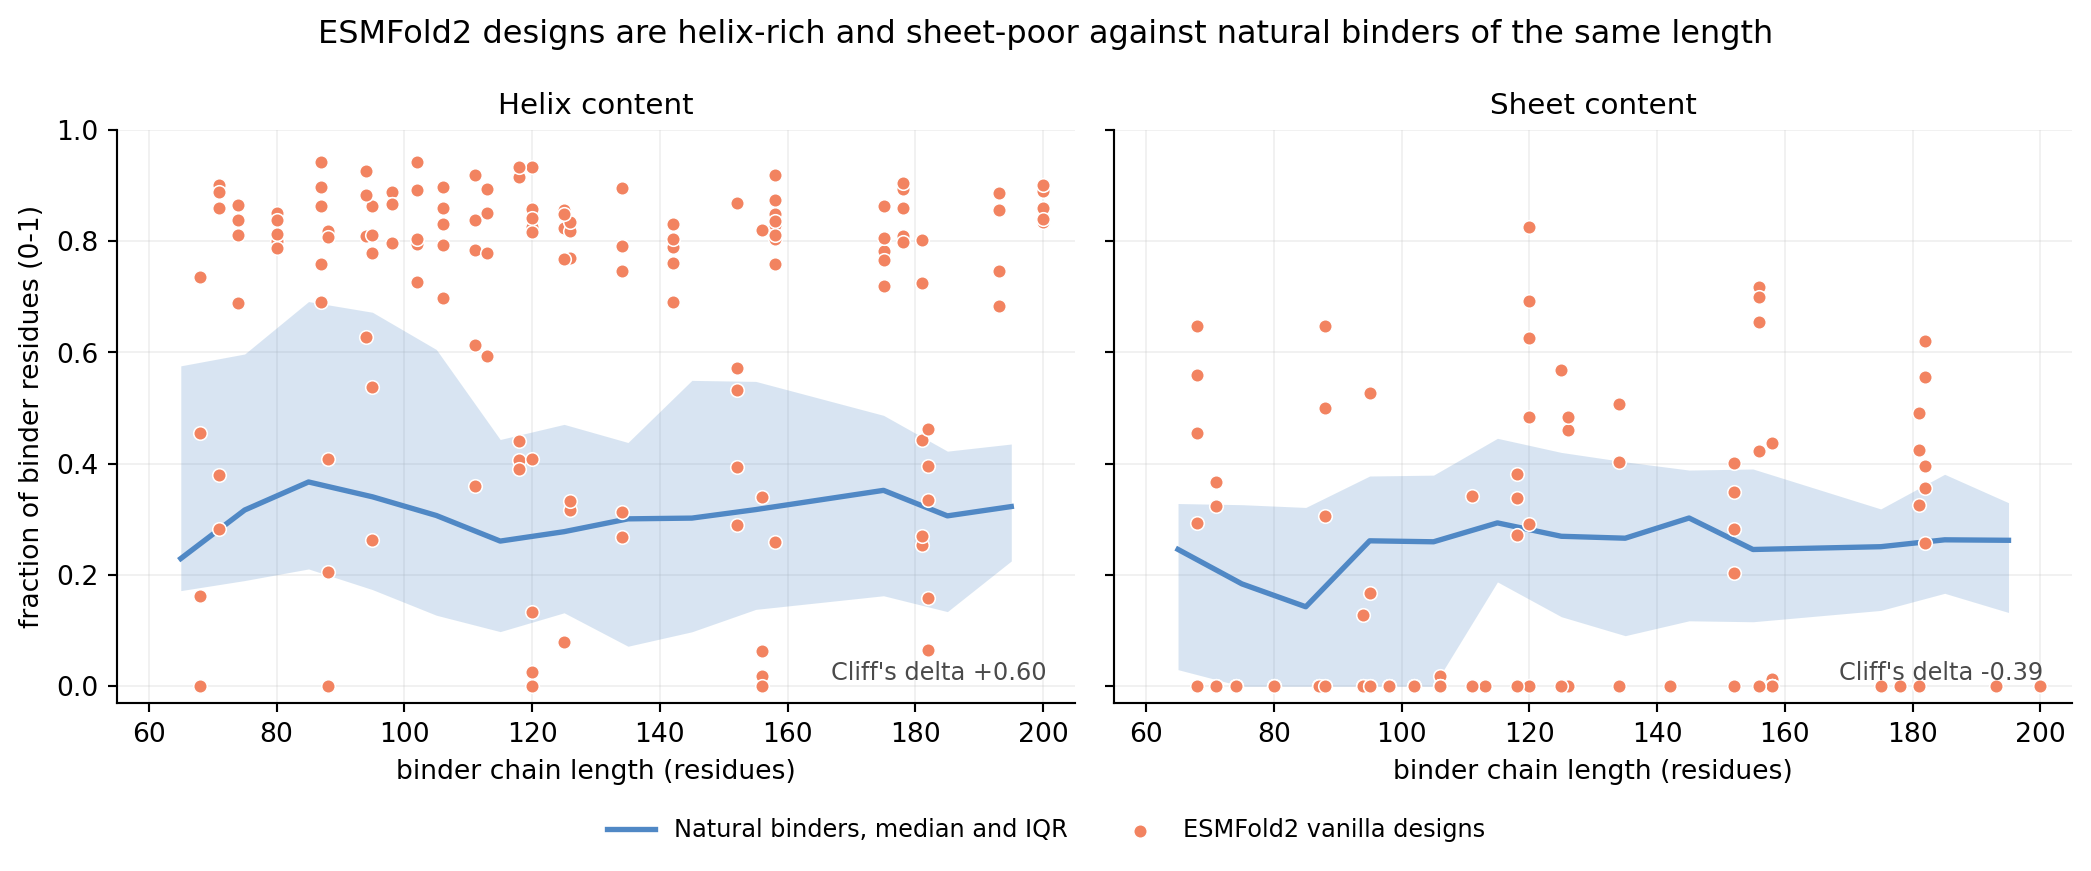

In [3]:
natural = reference.composition()
designs = composition.load_all(TARGETS, ["vanilla"])
matched = reference.length_matched(
    natural, designs["binder length (residues)"], "binder_sample_length_residues"
)

summary = pd.DataFrame(
    {
        "natural binders, length-matched (%)": [
            100 * matched["binder_helix_fraction"].mean(),
            100 * matched["binder_sheet_fraction"].mean(),
            100 * (matched["binder_sheet_fraction"] == 0).mean(),
        ],
        "ESMFold2 vanilla designs (%)": [
            100 * designs["helix (fraction 0-1)"].mean(),
            100 * designs["sheet (fraction 0-1)"].mean(),
            100 * (designs["sheet (fraction 0-1)"] == 0).mean(),
        ],
    },
    index=["mean helix", "mean sheet", "designs with zero sheet"],
).round(1)
display(summary)

fig = figures.composition_vs_length(matched, designs)

The bias is large and it is not subtle. The median design is **80% helix** against **31%** for a length-matched natural binder, and Cliff's delta of +0.60 puts the separation well past the conventional threshold for a large effect. Sheet runs the other way and harder: the median design contains **no sheet at all**, against 26% for the natural set.

The sheet deficit is the more striking half, but it needs one piece of calibration before it can be read. A single &beta;-free binder is unremarkable, because **20% of natural binders in this length range also have zero sheet**. What is remarkable is that **70% of designs do**. The model is not merely under-producing sheet; for most designs it is producing none.

This holds on every target. Median helix ranges only from 0.75 to 0.84 across the five, and median sheet is exactly zero on all five &mdash; including the four of five whose own fold is entirely &beta;. Whatever drives the preference is a property of the design procedure rather than something read off the target it is binding. The one nuance in the figure is that the designs' mean helix, 0.67, sits well below their median: a minority of designs are much less helical than the rest, so this is a strong central tendency rather than a hard floor.

:::{.callout-note collapse="true" title="How secondary structure is assigned, and what to distrust about the comparison"}
Labels come from [`pydssp`](https://github.com/ShintaroMinami/PyDSSP), a Kabsch&ndash;Sander implementation, collapsed to three states and reported as a fraction of binder residues. Both sides go through the same `analysis.secondary_structure` code, so the two are not measured by two different implementations of DSSP. Only residues with a complete N, C&alpha;, C and O backbone are labelled, so a residue missing from a model is missing from its denominator too.

The reference set comes from one RCSB query, recorded in `data/reference/natural_binder_search_hits.json` and rerunnable with `analysis.rcsb.build`: X-ray entries at 2.5 Å or better, exactly two polymer entities, heteromeric, a named source organism that is not "synthetic construct", and at least one entity of 60&ndash;200 residues, which is the range the design loop samples binder lengths from. Entities are clustered at 30% sequence identity and one representative per cluster is kept. That leaves 2,098 chains from 1,813 entries at median resolution 2.00 Å. Where both chains of an entry are in range, 53% of them, each takes its turn as the binder.

Now the things worth distrusting.

**"Binder" is a label we impose.** In a natural heterodimer neither chain is the binder; both are partners. Calling the 60&ndash;200-residue chain the binder is an analogy to the design setting, not a fact about the complex.

**Some partners are peptides, not domains.** Target chains run from 8 to 1,020 residues, and 15% are short enough to flag as peptide targets. A 100-residue protein gripping an 8-residue peptide is a different structural problem from a designed minibinder against a folded domain. These are flagged in the table rather than removed, so the flag can be used to test sensitivity.

**Some interfaces may not be real.** 13% are small enough to be crystal packing rather than function. Also flagged rather than removed.

**"Natural" is approximate.** 1% of binders and 3% of targets read as engineered scaffolds by description. Excluding "synthetic construct" as a source organism catches the obvious cases, not the subtle ones.

**The PDB is a convenience sample.** X-ray at 2.5 Å or better favours proteins that crystallise well, which favours compact, rigid, often &beta;-rich folds, and excludes cryo-EM and NMR entirely. 31% of binders are human. This is a sample of the binders that got solved, not of binders.

**Clustering at 30% identity does not remove structural redundancy.** Immunoglobulin-like folds recur across clusters that share little sequence.

**Composition is measured over resolved residues only**, a median 96% of each construct, which biases the natural coil fraction downward and makes the natural set look more ordered than the protein is in solution.

**The two sides sit on different kinds of coordinates.** The natural set is experimental; the designs are ESMFold2's own prediction, and predicted structures tend to have idealised secondary structure. That would inflate both helix *and* sheet in the designs, so it cannot explain a sheet deficit, but it does mean the coil comparison should be read loosely.
:::

## Question 2: Can we steer designs away from the &alpha;-rich basin?

Placeholder. The answer to establish here is yes, with a cost: helix content drops sharply, sheet and coil content rise, and interface confidence (ipTM) gets worse.

### How ESMFold2 designs a binder

Placeholder. Before the loss term can be explained, this section needs a compact description of the design algorithm:

- the target and the binder length,
- optimization over the binder's sequence representation by gradient descent through the folding model,
- the loss the vanilla campaign optimizes, and the confidence critic used to score the finished complex,
- how many steps a design runs for, and what is held fixed across arms.

A schematic (Figure 2) would earn its place here. Decide whether to draw one or to describe the loop in prose.

In [4]:
rows = []
for key in TARGETS:
    spec = targets.target(key)
    comp = secondary_structure.structure_composition(
        spec.structure_path, spec.chain, (spec.crop_start, spec.crop_end)
    )
    rows.append(
        {
            "target": spec.key,
            "protein": spec.protein,
            "construct (UniProt)": spec.construct_uniprot,
            "construct length (residues)": spec.construct_length,
            "resolution (Angstrom)": spec.resolution_angstrom,
            "target helix (%)": round(comp.helix_percent, 1),
            "target sheet (%)": round(comp.sheet_percent, 1),
            "target coil (%)": round(comp.coil_percent, 1),
        }
    )
pd.DataFrame(rows)

,target,protein,construct (UniProt),construct length (residues),resolution (Angstrom),target helix (%),target sheet (%),target coil (%)
0,egfr_d3,Human EGFR domain III,334-524,191,2.61,18.3,22.6,59.1
1,pdgfrb_d2d3,Human PDGFRB Ig-C2 domains 2-3,126-312,187,2.30,2.1,48.1,49.7
2,pdl1_igv,Human PD-L1 IgV domain,18-132,115,2.45,13.0,47.0,40.0
3,ctla4_igv,Human CTLA-4 IgV domain,38-155,118,1.80,2.5,52.5,44.9
4,cd45_d3d4,Human CD45 FN3 domains d3-d4,390-574,185,2.90,0.0,50.5,49.5


### The secondary-structure loss term

Placeholder. This section introduces the term added to the design loss: a capped logarithmic penalty on helical i&rarr;i+4 contacts computed from the predicted C&alpha; distogram, applied to the binder only, and added to the vanilla loss with a fixed weight.

What this section will cover:

- the definition of the term, written out as an equation,
- why it is computed from the distogram rather than from discrete secondary-structure labels,
- why the penalty is capped, and what the cap does to gradients late in a run,
- the weight used for the headline arm, and the fact that other terms and weights were searched before settling on this one.

Whether the search over alternative terms belongs in the pub, an appendix, or nowhere is an open question.

### Steering works

Placeholder. This section reports what the term does to fold composition, comparing the steered arms against the unsteered campaign on identical seeds.

Figure 3 goes in the cell below: per-design helix, sheet, and coil fraction (fraction of binder residues, 0&ndash;1) for each arm alongside the unsteered campaign.

In [5]:
steered = composition.load_all(TARGETS, ARMS)

pd.pivot_table(
    steered,
    index="target",
    columns="arm",
    values=["helix (fraction 0-1)", "sheet (fraction 0-1)"],
    aggfunc="median",
).round(3)[[
    ("helix (fraction 0-1)", arm) for arm in ARMS
] + [
    ("sheet (fraction 0-1)", arm) for arm in ARMS
]]

helix (fraction 0-1)                                    \
arm                      vanilla helix_logcap_w02 helix_logcap_w05   
target                                                               
cd45_d3d4                  0.753            0.070              0.0   
ctla4_igv                  0.837            0.065              0.0   
egfr_d3                    0.787            0.340              0.0   
pdgfrb_d2d3                0.767            0.023              0.0   
pdl1_igv                   0.832            0.707              0.0   

            sheet (fraction 0-1)                                    
arm                      vanilla helix_logcap_w02 helix_logcap_w05  
target                                                              
cd45_d3d4                    0.0            0.136            0.612  
ctla4_igv                    0.0            0.515            0.587  
egfr_d3                      0.0            0.332            0.590  
pdgfrb_d2d3                  0.0            0.596            0.597  
pdl1_igv                     0.0            0.000            0.611

Placeholder. Per-step traces show when during a run the fold class is decided, which is worth a paragraph and possibly a figure. The per-step loss logs in `data/campaigns/*/step_trace.parquet` are what this reads.

### The cost: interface confidence suffers

Placeholder. This section reports the side effect. Steered arms lose interface confidence relative to the unsteered campaign, and the size of that loss grows with the steering weight.

Figure 4 goes in the cell below: steering strength versus interface confidence (ipTM, 0&ndash;1) and binder pLDDT (0&ndash;100) per arm.

The paragraph after the figure has to be careful: a drop in a confidence metric is not by itself a drop in design quality. That distinction is exactly what Question 3 is for.

In [6]:
pd.pivot_table(
    steered,
    index="target",
    columns="arm",
    values=["iptm (0-1)", "binder pLDDT (0-100)"],
    aggfunc="median",
).round(2)[[
    ("iptm (0-1)", arm) for arm in ARMS
] + [
    ("binder pLDDT (0-100)", arm) for arm in ARMS
]]

iptm (0-1)                                   binder pLDDT (0-100)  \
arm            vanilla helix_logcap_w02 helix_logcap_w05              vanilla   
target                                                                          
cd45_d3d4         0.84             0.80             0.64                80.93   
ctla4_igv         0.89             0.82             0.66                89.68   
egfr_d3           0.94             0.91             0.88                87.50   
pdgfrb_d2d3       0.89             0.86             0.83                82.86   
pdl1_igv          0.95             0.92             0.91                89.16   

                                               
arm         helix_logcap_w02 helix_logcap_w05  
target                                         
cd45_d3d4              74.66            65.19  
ctla4_igv              81.23            67.54  
egfr_d3                84.85            72.65  
pdgfrb_d2d3            77.24            71.15  
pdl1_igv               82.39            73.62

## Question 3: Is it model bias?

Placeholder, and the one section whose answer is not yet known. **These experiments have not run.** Nothing below should be read as a result.

The question: when a steered, &beta;-richer design scores poorly on interface confidence, is that because the design is genuinely worse, or because ESMFold2 systematically assigns lower confidence to &beta;-rich structures regardless of their quality?

The planned test: score reference structures of known quality from the RCSB, spanning a range of secondary-structure composition, and ask whether the model's confidence tracks fold class on structures that are known to be real.

Figure 5 goes in the cell below: model confidence versus secondary-structure composition (fraction of residues, 0&ndash;1) across the RCSB reference set.

The two branches, to be resolved by the experiment, not by writing:

- **If yes, it is model bias.** The confidence penalty on &beta;-rich designs is at least partly an artifact, the steered designs are not as bad as their scores suggest, and the takeaway is that they are worth trialing experimentally.
- **If no.** The confidence drop reflects genuinely poorer designs, and the takeaway shifts to the fraction of steered designs that clear a viability bar anyway, and to how much steering can be applied before that fraction collapses.

In [7]:
print("Question 3 has not been run.")
print("Two problems are recorded in the project notes and must be resolved first:")
print("  1. Scoring designs with ESMFold2's own iptm and pLDDT is circular.")
print("  2. The readout adds Calpha RMSD of the refold against deposited coordinates.")

Question 3 has not been run.
Two problems are recorded in the project notes and must be resolved first:
  1. Scoring designs with ESMFold2's own iptm and pLDDT is circular.
  2. The readout adds Calpha RMSD of the refold against deposited coordinates.


## Takeaways

Placeholder for the summary, which branches on Question 3 and so cannot be written yet. The two sections after it do not depend on that answer.

### Summary

Placeholder. Two or three sentences: basal &alpha;-richness is high, a loss term steers away from it, interface confidence pays for it, and Question 3 decides whether that payment is real. Write this after Question 3 resolves.

### A loss term is a tuning handle, and secondary structure is one thing to tune

The steering result matters less for what it does to helices than for what it says about the method. A differentiable term added to the design loss changed the fold class of the output without retraining anything and without touching the model weights. The handle is the distogram the design loop already optimizes against, and it was sitting there unused.

That reframes the contribution. This is not a paper about helices. It is a worked example of adding a constraint to ESMFold2's binder design algorithm, with the measurements needed to say honestly what the constraint bought and what it cost.

The limits we ran into are part of the example, and they generalize:

- The term stops acting once the property it penalizes is already saturated, so **when** a term applies during the run matters as much as how strongly.
- Pushing harder on one property costs confidence in another, so any added term needs its tradeoff mapped rather than asserted.
- The optimizer will satisfy a loss the cheapest way available, which is not always the way you intended.

Anyone adding a term to this design loop should expect all three.

### A binder is the start of a drug program, not the end

Nothing in this work produces a therapeutic. A design that binds its target with good predicted confidence has cleared the first of many gates. Downstream, a candidate still has to be developable: expressible and soluble at concentration, stable on the shelf, non-aggregating, humanized or otherwise non-immunogenic, free of manufacturing and post-translational liabilities, and specific enough not to bind everything else in the proteome.

Each of those is a property of a sequence or a structure. That is the interesting part, because it is the same kind of object the secondary-structure term acts on. In principle every one of them is expressible as a term on the distogram or on the sequence logits, and added to the same objective in the same place.

Sequence liabilities are the nearest example, and one worth tuning rather than ignoring. Steering the fold also changes the sequences that come out, so a term that optimizes structure alone can quietly degrade a property nobody was watching. We did not write a liability term here, and the designs in this work should not be read as developable. Adding one is the obvious next thing to try, and it would test whether the tuning handle generalizes beyond the property we happened to pick.

That is the claim we want to leave the reader with: ESMFold2's binder design algorithm exposes a place to put constraints, secondary structure is one constraint that demonstrably works there, and the constraints a drug program actually cares about are the reason to care.

## Next steps

Placeholder. What we would do next, and what someone else could pick up. Fill in once the takeaways are settled.

## An open question: objective or weights?

Everything here changes behavior without changing the model. The steering happens in the design loop, on top of frozen weights, and that is worth naming as a choice rather than a default, because there is an obvious alternative: retrain or fine-tune so that the model produces the distribution you want natively.

The two routes are not equivalent, and our results show some of the difference. Steering from the objective fights the model's prior instead of altering it, which may be why interface confidence pays a price, and why the optimizer sometimes satisfies the term in ways we did not intend. A model whose weights had learned the target distribution would presumably not need to be argued with in the same way.

But the comparison is lopsided on cost. Adding a term to the loss is a few lines and a single campaign. Retraining a structure prediction model of this scale means substantial compute, a training corpus assembled for the property you want, and revalidation of everything the base model was already good at, with the risk of degrading it. For a property you might only want occasionally, or want in three mutually exclusive variants, that is a steep price. Post-hoc terms are also composable, inspectable, and trivially reversible, which weight updates are not.

So we would pose it as a question rather than answer it. Which behaviors belong in the weights, and which belong in the objective? Is there a principled boundary, drawn perhaps by how fundamental a property is or how often it is wanted, or is the line mostly economic and therefore likely to move as training costs fall? We do not know, and the honest position from this work is that the objective route is cheap enough to be worth exhausting before anyone reaches for the weights.